In [1]:
import pandas as pd, joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("../data/raw/crop_recommendation.csv").dropna()
X, y = df.drop(columns="label"), df["label"]
scaler = StandardScaler().fit(X)
Xtr, Xte, ytr, yte = train_test_split(scaler.transform(X), y, test_size=0.2, random_state=1, stratify=y)

models = {"Decision Tree": DecisionTreeClassifier(),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier(200, random_state=1)}
for name, m in models.items():
    m.fit(Xtr, ytr)
    print(name, accuracy_score(yte, m.predict(Xte)), cross_val_score(m, Xtr, ytr, cv=5).mean())

Decision Tree 0.990909090909091 0.9880681818181818
KNN 0.9727272727272728 0.965340909090909
Random Forest 0.9977272727272727 0.99375


In [3]:
%pip install seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install --upgrade seaborn

Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      0.95      0.97        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

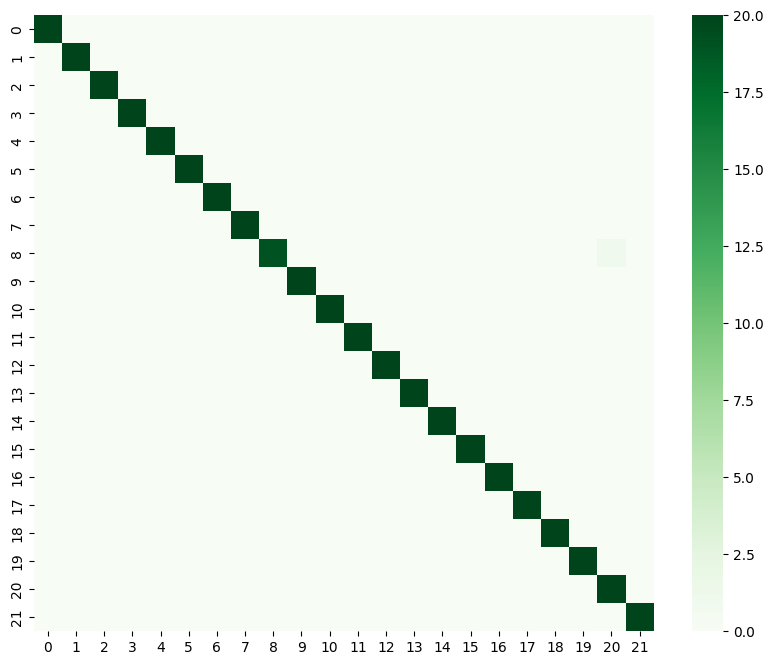

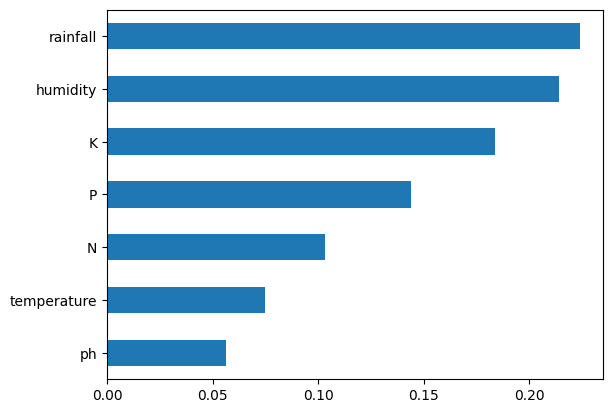

['../models/scaler.pkl']

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix   # skip if already imported

best = models["Random Forest"]
print(classification_report(yte, best.predict(Xte)))

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(yte, best.predict(Xte)), cmap="Greens")
plt.show()

pd.Series(best.feature_importances_, index=X.columns).sort_values().plot.barh()
plt.show()

joblib.dump(best, "../models/crop_recommendation_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")